# Campaign Response Analysis 

**Dataset:** The notebook uses `data/raw/set_d.csv`. If the CSV is not present, it automatically creates a clearly labelled synthetic practice dataset with the required columns (`record_id`, `visits`, `recency`, `engagement`, `spend`, `group`, `response`). Replace it with your teacher-provided dataset before final submission if required.

**Run:** Execute cells from top to bottom. Output tables, figures, and models are saved in `outputs/` and `models/`.

In [13]:

from pathlib import Path
import tensorflow as tf
import warnings
import subprocess
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from scipy.stats import ttest_ind, t
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, silhouette_score, classification_report
)
from sklearn.cluster import KMeans

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

# =========================================================
# 1. PROJECT PATHS
# =========================================================

PROJECT_DIR = Path.cwd()

DATA = PROJECT_DIR / "data" / "raw" / "set_d.csv"

if not DATA.exists():
    candidates = list(PROJECT_DIR.rglob("set_d.csv"))

    if candidates:
        DATA = candidates[0]
    else:
        raise FileNotFoundError(
            "set_d.csv was not found.\n"
            "Please place it inside data/raw/set_d.csv "
            "in your project folder."
        )

FIG = PROJECT_DIR / "outputs" / "figures"
TAB = PROJECT_DIR / "outputs" / "tables"
MOD = PROJECT_DIR / "models"

for folder in [FIG, TAB, MOD]:
    folder.mkdir(parents=True, exist_ok=True)

# =========================================================
# 2. LOAD DATASET
# =========================================================

raw = pd.read_csv(DATA)

raw.columns = raw.columns.str.strip()

if "record_id" not in raw.columns:
    raw.insert(
        0,
        "record_id",
        [f"R{i+1:03d}" for i in range(len(raw))]
    )

required_columns = [
    "visits",
    "recency",
    "engagement",
    "spend",
    "group",
    "response"
]

missing_columns = [
    col for col in required_columns
    if col not in raw.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}\n"
        f"Available columns: {raw.columns.tolist()}"
    )

print("=" * 50)
print("DATASET LOADED SUCCESSFULLY")
print("=" * 50)
print("Dataset path:", DATA.resolve())
print("Dataset shape:", raw.shape)
print("Column names:", raw.columns.tolist())

display(raw.head())

print("\nMissing values:")
display(raw.isnull().sum().to_frame("Missing Count"))

print("\nDuplicate rows:", raw.duplicated().sum())


DATASET LOADED SUCCESSFULLY
Dataset path: C:\Campaign_Response_Updated_Project\Campaign_Response_Updated_Project\data\raw\set_d.csv
Dataset shape: (300, 7)
Column names: ['record_id', 'visits', 'recency', 'engagement', 'spend', 'group', 'response']


,record_id,visits,recency,engagement,spend,group,response
0,R001,8.0,30.0,55.007412,1291.975051,G2,1
1,R002,7.0,40.0,71.504176,960.227272,G1,1
2,R003,7.0,75.0,51.192559,1296.856714,G1,0
3,R004,2.0,67.0,28.365768,1049.084552,G2,1
4,R005,6.0,70.0,40.475155,660.502628,G1,0



Missing values:


,Missing Count
record_id,0
visits,3
recency,0
engagement,3
spend,3
group,0
response,0



Duplicate rows: 0


In [14]:
# 1. AUDIT AND CLEAN
# =========================================================

print("\n========== DATA AUDIT ==========")
print("Raw shape:", raw.shape)
print("Missing counts:\n", raw.isna().sum())
print("Exact duplicates:", raw.duplicated().sum())
print("Target counts:\n", raw["response"].value_counts().sort_index())

df = raw.drop_duplicates().reset_index(drop=True)
print("After duplicate removal:", df.shape)

# Validate target values before stratified splitting
if df["response"].isna().any():
    raise ValueError("The response column contains missing values. Clean them before splitting.")

if df["response"].nunique() < 2:
    raise ValueError("The response column must contain at least two classes for stratified splitting.")

print("Dataset audit completed. Row count:", len(df))

# =========================================================


========== DATA AUDIT ==========
Raw shape: (300, 7)
Missing counts:
 record_id     0
visits        3
recency       0
engagement    3
spend         3
group         0
response      0
dtype: int64
Exact duplicates: 0
Target counts:
 response
0    131
1    169
Name: count, dtype: int64
After duplicate removal: (300, 7)
Dataset audit completed. Row count: 300


In [15]:
# 2. STRATIFIED TRAIN / VALIDATION / TEST SPLIT
# =========================================================

train_df, test_df = train_test_split(
    df,
    test_size=0.20,
    stratify=df["response"],
    random_state=RANDOM_STATE
)

fit_df, val_df = train_test_split(
    train_df,
    test_size=0.20,
    stratify=train_df["response"],
    random_state=RANDOM_STATE
)

print("\n========== PARTITIONS ==========")
print("Fit:", len(fit_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

split_ids = {
    "fit": fit_df["record_id"].tolist(),
    "validation": val_df["record_id"].tolist(),
    "test": test_df["record_id"].tolist()
}
with open(TAB / "split_ids.json", "w", encoding="utf-8") as f:
    json.dump(split_ids, f, indent=2)

assert set(split_ids["fit"]).isdisjoint(split_ids["validation"])
assert set(split_ids["fit"]).isdisjoint(split_ids["test"])
assert set(split_ids["validation"]).isdisjoint(split_ids["test"])

pd.DataFrame({
    "partition": ["fit", "validation", "test"],
    "n": [len(fit_df), len(val_df), len(test_df)]
}).to_csv(TAB / "split_summary.csv", index=False)

# =========================================================


========== PARTITIONS ==========
Fit: 192
Validation: 48
Test: 60


In [19]:
# 3. TASK 1 — MATHS & ADVANCED STATISTICS
# =========================================================


eng = fit_df["engagement"].dropna()

if len(eng) < 2:
    raise ValueError("At least two non-missing engagement values are needed for statistics.")

stats = pd.DataFrame([{
    "fit_records_n": len(fit_df),
    "observed_n": len(eng),
    "mean": eng.mean(),
    "median": eng.median(),
    "sample_std_ddof1": eng.std(ddof=1)
}])
stats.to_csv(TAB / "statistics_summary.csv", index=False)

plt.figure(figsize=(7, 4))
plt.hist(eng, bins=15)
plt.title("Engagement Distribution — Fit Records")
plt.xlabel("Engagement")
plt.ylabel("Frequency")
plt.tight_layout()
plt.savefig(FIG / "engagement_histogram.png", dpi=150)
plt.close()

g1 = fit_df.loc[
    (fit_df["group"] == "G1") & fit_df["engagement"].notna(),
    "engagement"
]
g2 = fit_df.loc[
    (fit_df["group"] == "G2") & fit_df["engagement"].notna(),
    "engagement"
]

tt = ttest_ind(g1, g2, equal_var=False)

mean = eng.mean()
se = eng.std(ddof=1) / np.sqrt(len(eng))
critical = t.ppf(0.975, len(eng) - 1)
ci = (mean - critical * se, mean + critical * se)

inference = pd.DataFrame([{
    "G1_n": len(g1),
    "G2_n": len(g2),
    "G1_mean": g1.mean(),
    "G2_mean": g2.mean(),
    "welch_t": tt.statistic,
    "p_value": tt.pvalue,
    "alpha": 0.05,
    "overall_n": len(eng),
    "overall_mean": mean,
    "ci95_low": ci[0],
    "ci95_high": ci[1]
}])
inference.to_csv(TAB / "inference_results.csv", index=False)

complete = fit_df[["engagement", "visits"]].dropna()
X = complete.to_numpy(dtype=float)
X_centered = X - X.mean(axis=0)

cov = (X_centered.T @ X_centered) / (len(X_centered) - 1)
eigvals, eigvecs = np.linalg.eigh(cov)
order = np.argsort(eigvals)[::-1]
eigvals, eigvecs = eigvals[order], eigvecs[:, order]
variance_share = eigvals[0] / eigvals.sum()

pd.DataFrame(
    cov,
    index=["engagement", "visits"],
    columns=["engagement", "visits"]
).to_csv(TAB / "covariance_matrix.csv")

pd.DataFrame({
    "eigenvalue": eigvals,
    "variance_share": eigvals / eigvals.sum()
}).to_csv(TAB / "eigenvalues.csv", index=False)

pd.DataFrame(
    eigvecs,
    index=["engagement", "visits"]
).to_csv(TAB / "eigenvectors.csv")

print("\n========== TASK 1 ==========")
print(stats.to_string(index=False))
print(inference.to_string(index=False))
print("Covariance matrix:\n", cov)
print("Largest eigenvalue variance share:", variance_share)

print("Total fit records:", len(fit_df))
print("Observed engagement values:", eng.count())
print("Mean:", eng.mean())
print("Median:", eng.median())
print("Standard deviation:", eng.std(ddof=1))



========== TASK 1 ==========
 fit_records_n  observed_n      mean    median  sample_std_ddof1
           192         190 54.712665 54.687087          12.91508
 G1_n  G2_n   G1_mean   G2_mean  welch_t  p_value  alpha  overall_n  overall_mean  ci95_low  ci95_high
   89   101 56.142428 53.452775 1.424753 0.155994   0.05        190     54.712665 52.864425  56.560904
Covariance matrix:
 [[166.57494283  11.85615442]
 [ 11.85615442   4.75930079]]
Largest eigenvalue variance share: 0.9772653727977628
Total fit records: 192
Observed engagement values: 190
Mean: 54.71266482306926
Median: 54.687086642066156
Standard deviation: 12.915079941247399


In [ ]:
# 4. TASK 2 — PREPROCESSING AND ENGINEERING
# =========================================================
numeric = ["visits","recency","engagement","spend"]
categorical = ["group"]
target = "response"

imputer = SimpleImputer(strategy="median")
fit_num = pd.DataFrame(
    imputer.fit_transform(fit_df[numeric]),
    columns=numeric, index=fit_df.index
)
val_num = pd.DataFrame(
    imputer.transform(val_df[numeric]),
    columns=numeric, index=val_df.index
)
test_num = pd.DataFrame(
    imputer.transform(test_df[numeric]),
    columns=numeric, index=test_df.index
)

for frame in [fit_num, val_num, test_num]:
    frame["engineered_feature"] = frame["engagement"]/(frame["recency"]+1)

num_features = numeric + ["engineered_feature"]
scaler = StandardScaler()
fit_scaled = pd.DataFrame(
    scaler.fit_transform(fit_num[num_features]),
    columns=num_features, index=fit_num.index
)
val_scaled = pd.DataFrame(
    scaler.transform(val_num[num_features]),
    columns=num_features, index=val_num.index
)
test_scaled = pd.DataFrame(
    scaler.transform(test_num[num_features]),
    columns=num_features, index=test_num.index
)

encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
fit_group = encoder.fit_transform(fit_df[categorical])
val_group = encoder.transform(val_df[categorical])
test_group = encoder.transform(test_df[categorical])
group_names = list(encoder.get_feature_names_out(categorical))

fit_group = pd.DataFrame(fit_group, columns=group_names, index=fit_df.index)
val_group = pd.DataFrame(val_group, columns=group_names, index=val_df.index)
test_group = pd.DataFrame(test_group, columns=group_names, index=test_df.index)

X_fit = pd.concat([fit_scaled, fit_group], axis=1)
X_val = pd.concat([val_scaled, val_group], axis=1)
X_test = pd.concat([test_scaled, test_group], axis=1)

y_fit = fit_df[target].astype(int)
y_val = val_df[target].astype(int)
y_test = test_df[target].astype(int)

assert target not in X_fit.columns
assert "record_id" not in X_fit.columns
assert np.isfinite(X_fit.to_numpy()).all()
assert np.isfinite(X_val.to_numpy()).all()
assert np.isfinite(X_test.to_numpy()).all()

pd.DataFrame({
    "feature": X_fit.columns,
    "kind": [
        "scaled_numeric" if c in num_features else "unscaled_group_onehot"
        for c in X_fit.columns
    ]
}).to_csv(TAB/"preprocessing_audit.csv", index=False)

joblib.dump(imputer, MOD/"imputer.joblib")
joblib.dump(scaler, MOD/"scaler.joblib")
joblib.dump(encoder, MOD/"group_encoder.joblib")

print("\n========== TASK 2 ==========")
print("Fit shape:", X_fit.shape)
print("Validation shape:", X_val.shape)
print("Test shape:", X_test.shape)
print("Feature names:", list(X_fit.columns))

# =========================================================


========== TASK 2 ==========
Fit shape: (192, 7)
Validation shape: (48, 7)
Test shape: (60, 7)
Feature names: ['visits', 'recency', 'engagement', 'spend', 'engineered_feature', 'group_G1', 'group_G2']



========== TASK 3 ==========
             model  accuracy  precision_positive_1  recall_positive_1  f1_positive_1
   DummyClassifier  0.566667              0.566667           1.000000       0.723404
LogisticRegression  0.650000              0.696970           0.676471       0.686567
Confusion matrix:
 [[16 10]
 [11 23]]


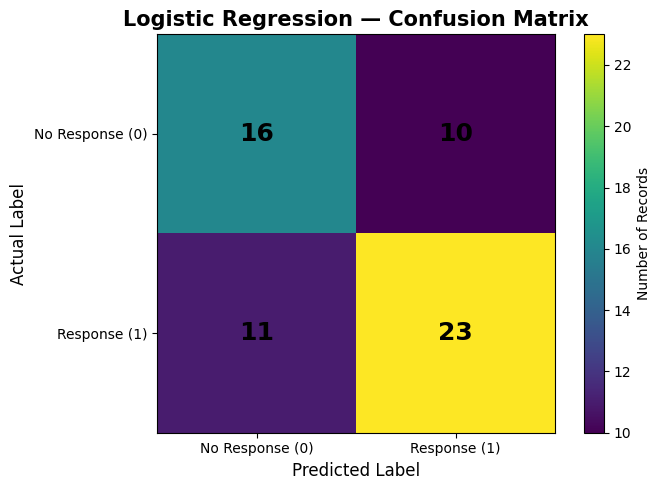

In [ ]:
# 5. TASK 3 — SUPERVISED LEARNING
# =========================================================
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_fit, y_fit)
dummy_pred = dummy.predict(X_test)

lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_fit, y_fit)
lr_pred = lr.predict(X_test)
lr_prob = lr.predict_proba(X_test)[:,1]

def metric_row(model, yt, yp):
    return {
        "model": model,
        "accuracy": accuracy_score(yt, yp),
        "precision_positive_1": precision_score(yt, yp, zero_division=0),
        "recall_positive_1": recall_score(yt, yp, zero_division=0),
        "f1_positive_1": f1_score(yt, yp, zero_division=0)
    }

metrics = pd.DataFrame([
    metric_row("DummyClassifier", y_test, dummy_pred),
    metric_row("LogisticRegression", y_test, lr_pred)
])
metrics.to_csv(TAB/"baseline_logistic_metrics.csv", index=False)

cm = confusion_matrix(y_test, lr_pred, labels=[0,1])
pd.DataFrame(cm, index=["actual_0","actual_1"],
             columns=["predicted_0","predicted_1"]).to_csv(
    TAB/"logistic_confusion_matrix.csv"
)

pd.DataFrame({
    "record_id": test_df["record_id"].to_numpy(),
    "true_label": y_test.to_numpy(),
    "predicted_label": lr_pred,
    "class_1_probability": lr_prob
}).to_csv(TAB/"logistic_test_predictions.csv", index=False)

joblib.dump(lr, MOD/"logistic_regression.joblib")
joblib.dump(dummy, MOD/"dummy_classifier.joblib")

print("\n========== TASK 3 ==========")
print(metrics.to_string(index=False))
print("Confusion matrix:\n", cm)



plt.figure(figsize=(7, 5))

plt.imshow(cm)

plt.title(
    "Logistic Regression — Confusion Matrix",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Predicted Label", fontsize=12)
plt.ylabel("Actual Label", fontsize=12)

plt.xticks(
    [0, 1],
    ["No Response (0)", "Response (1)"]
)

plt.yticks(
    [0, 1],
    ["No Response (0)", "Response (1)"]
)

# Add values inside matrix
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(
            j,
            i,
            str(cm[i, j]),
            ha="center",
            va="center",
            fontsize=18,
            fontweight="bold"
        )

plt.colorbar(label="Number of Records")

plt.grid(False)

plt.tight_layout()

# Save figure
plt.savefig(
    FIG / "logistic_confusion_matrix.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

# =========================================================

In [ ]:
# 6. TASK 4 — K-MEANS
# =========================================================
cluster_X = fit_scaled.to_numpy()
cluster_rows = []

for k in [2,3,4]:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(cluster_X)
    cluster_rows.append({
        "k": k,
        "inertia": km.inertia_,
        "silhouette": silhouette_score(cluster_X, labels)
    })

cluster_scores = pd.DataFrame(cluster_rows)
best_k = int(cluster_scores.sort_values(
    ["silhouette","k"], ascending=[False,True]
).iloc[0]["k"])
cluster_scores.to_csv(TAB/"k_selection_scores.csv", index=False)

best_km = KMeans(n_clusters=best_k, n_init=10, random_state=42)
labels = best_km.fit_predict(cluster_X)

profiles = fit_num.copy()
profiles["cluster"] = labels
profiles.groupby("cluster")[num_features].mean().to_csv(
    TAB/"cluster_profiles.csv"
)

joblib.dump(best_km, MOD/"kmeans_best.joblib")

print("\n========== TASK 4 ==========")
print(cluster_scores.to_string(index=False))
print("Selected k:", best_k)
print("Cluster profiles:\n", profiles.groupby("cluster")[num_features].mean())

# =========================================================




========== TASK 4 ==========
 k    inertia  silhouette
 2 745.410081    0.239308
 3 599.467726    0.230381
 4 497.928059    0.217568
Selected k: 2
Cluster profiles:
            visits    recency  engagement        spend  engineered_feature
cluster                                                                  
0        4.007937  55.269841   48.851019  1261.649395            1.265580
1        6.666667  30.500000   65.902304  1459.667661            5.313273


In [ ]:
# 7. TASK 5 — ANN
# =========================================================
try:
    import tensorflow as tf
    tf.keras.utils.set_random_seed(42)

    ann = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(X_fit.shape[1],)),
        tf.keras.layers.Dense(16, activation="relu"),
        tf.keras.layers.Dense(8, activation="relu"),
        tf.keras.layers.Dense(1, activation="sigmoid")
    ])

    ann.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    ann.summary()

    early_stop = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=5, restore_best_weights=True
    )

    history = ann.fit(
        X_fit.to_numpy(), y_fit.to_numpy(),
        validation_data=(X_val.to_numpy(), y_val.to_numpy()),
        epochs=50, batch_size=16,
        callbacks=[early_stop], verbose=0
    )

    test_loss, test_acc = ann.evaluate(
        X_test.to_numpy(), y_test.to_numpy(), verbose=0
    )
    prob = ann.predict(X_test.to_numpy(), verbose=0).ravel()
    ann_pred = (prob >= 0.5).astype(int)

    ann_metrics = pd.DataFrame([
        metric_row("ANN", y_test, ann_pred)
    ])
    ann_metrics["test_loss"] = test_loss
    ann_metrics["epochs_ran"] = len(history.history["loss"])
    ann_metrics.to_csv(TAB/"ann_metrics.csv", index=False)

    pd.DataFrame({
        "record_id": test_df["record_id"].to_numpy(),
        "true_label": y_test.to_numpy(),
        "predicted_label": ann_pred,
        "class_1_probability": prob
    }).to_csv(TAB/"ann_test_predictions.csv", index=False)

    pd.DataFrame(history.history).to_csv(
        TAB/"ann_training_history.csv", index=False
    )

    plt.figure(figsize=(7,4))
    plt.plot(history.history["loss"], label="training loss")
    plt.plot(history.history["val_loss"], label="validation loss")
    plt.title("ANN Training and Validation Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Binary cross-entropy loss")
    plt.legend()
    plt.tight_layout()
    plt.savefig(FIG/"ann_loss_curve.png", dpi=150)
    plt.close()

    ann.save(MOD/"campaign_response_ann.keras")

    comparison = pd.concat([
        metrics,
        ann_metrics[["model","accuracy","precision_positive_1",
                     "recall_positive_1","f1_positive_1"]]
    ], ignore_index=True)
    comparison.to_csv(TAB/"model_comparison.csv", index=False)

    print("\n========== TASK 5 ==========")
    print(ann_metrics.to_string(index=False))
    print("Epochs actually run:", len(history.history["loss"]))
    print("ANN test accuracy:", test_acc)

    

except ImportError:
    print("\nTensorFlow is not installed.")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 273 (1.07 KB)

 Trainable params: 273 (1.07 KB)

 Non-trainable params: 0 (0.00 B)


========== TASK 5 ==========
model  accuracy  precision_positive_1  recall_positive_1  f1_positive_1  test_loss  epochs_ran
  ANN  0.683333              0.727273           0.705882       0.716418   0.622604          50
Epochs actually run: 50
ANN test accuracy: 0.6833333373069763



IMPROVED ARTIFICIAL NEURAL NETWORK

ANN Architecture:


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 32)             │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16)             │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,121 (4.38 KB)

 Trainable params: 1,025 (4.00 KB)

 Non-trainable params: 96 (384.00 B)

Epoch 1/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.5469 - loss: 0.8883 - val_accuracy: 0.4583 - val_loss: 0.7417 - learning_rate: 0.0010
Epoch 2/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.5208 - loss: 0.8212 - val_accuracy: 0.5000 - val_loss: 0.7133 - learning_rate: 0.0010
Epoch 3/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.5677 - loss: 0.7466 - val_accuracy: 0.4792 - val_loss: 0.6967 - learning_rate: 0.0010
Epoch 4/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.5677 - loss: 0.7745 - val_accuracy: 0.5000 - val_loss: 0.6808 - learning_rate: 0.0010
Epoch 5/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.5729 - loss: 0.7168 - val_accuracy: 0.5000 - val_loss: 0.6729 - learning_rate: 0.0010
Epoch 6/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6146 - loss: 0.6862 - val_accuracy: 0.5625 - val_loss: 0.6713 - learning_rate: 0.0010
Epoch 7/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.5677 - loss: 0.7050 - val

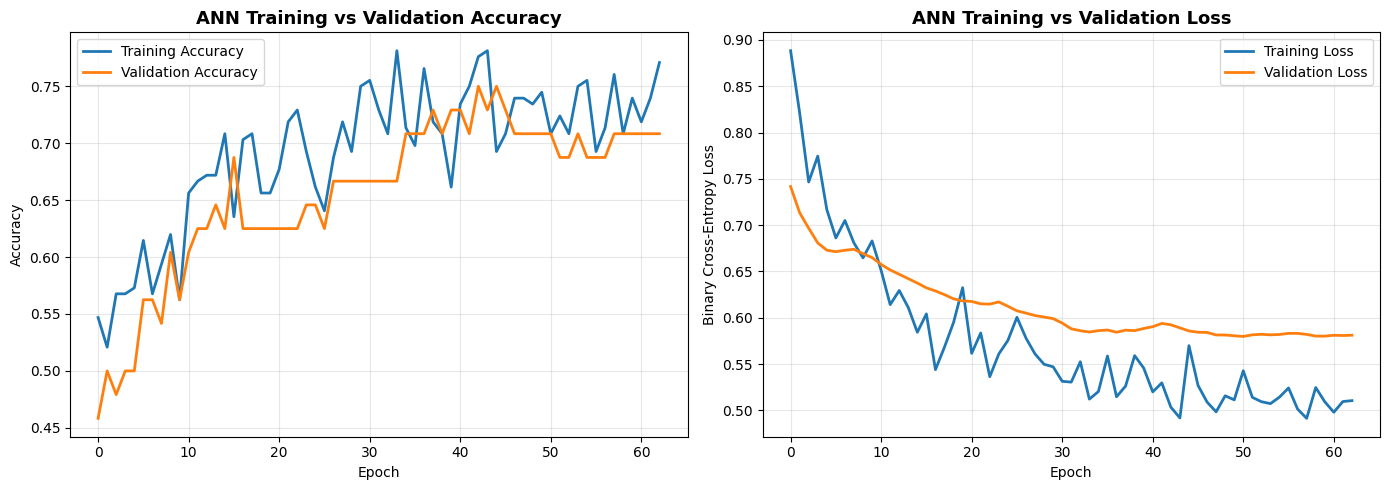

In [ ]:
# =========================================================
# TASK 5 — IMPROVED ANN
# =========================================================

tf.keras.utils.set_random_seed(42)

print("\n" + "=" * 60)
print("IMPROVED ARTIFICIAL NEURAL NETWORK")
print("=" * 60)

# ---------------------------------------------------------
# 1. Build improved ANN
# ---------------------------------------------------------

ann = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_fit.shape[1],)),

    tf.keras.layers.Dense(
        32,
        activation="relu",
        kernel_initializer="he_normal"
    ),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(0.15),

    tf.keras.layers.Dense(
        16,
        activation="relu",
        kernel_initializer="he_normal"
    ),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(0.10),

    tf.keras.layers.Dense(
        8,
        activation="relu",
        kernel_initializer="he_normal"
    ),

    tf.keras.layers.Dense(
        1,
        activation="sigmoid"
    )
])

# ---------------------------------------------------------
# 2. Compile
# ---------------------------------------------------------

ann.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("\nANN Architecture:")
ann.summary()

# ---------------------------------------------------------
# 3. Callbacks
# ---------------------------------------------------------

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=12,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=5,
    min_lr=1e-5,
    verbose=1
)

# ---------------------------------------------------------
# 4. Train ANN
# ---------------------------------------------------------

history = ann.fit(
    X_fit,
    y_fit,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=16,
    callbacks=[
        early_stop,
        reduce_lr
    ],
    verbose=1
)

# ---------------------------------------------------------
# 5. Validation prediction
# ---------------------------------------------------------

val_probability = ann.predict(
    X_val,
    verbose=0
).ravel()

val_prediction = (
    val_probability >= 0.5
).astype(int)

# ---------------------------------------------------------
# 6. Test prediction
# ---------------------------------------------------------

test_probability = ann.predict(
    X_test,
    verbose=0
).ravel()

test_prediction = (
    test_probability >= 0.5
).astype(int)

# ---------------------------------------------------------
# 7. Metrics
# ---------------------------------------------------------

ann_accuracy = accuracy_score(
    y_test,
    test_prediction
)

ann_precision = precision_score(
    y_test,
    test_prediction,
    zero_division=0
)

ann_recall = recall_score(
    y_test,
    test_prediction,
    zero_division=0
)

ann_f1 = f1_score(
    y_test,
    test_prediction,
    zero_division=0
)

print("\n" + "=" * 60)
print("ANN TEST RESULTS")
print("=" * 60)

print(f"Accuracy  : {ann_accuracy:.4f}")
print(f"Accuracy %: {ann_accuracy * 100:.2f}%")
print(f"Precision : {ann_precision:.4f}")
print(f"Recall    : {ann_recall:.4f}")
print(f"F1 Score  : {ann_f1:.4f}")

# ---------------------------------------------------------
# 8. Confusion Matrix
# ---------------------------------------------------------

cm = confusion_matrix(
    y_test,
    test_prediction
)

print("\nConfusion Matrix:")
print(cm)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        test_prediction,
        zero_division=0
    )
)

# ---------------------------------------------------------
# 9. Accuracy + Loss curves
# ---------------------------------------------------------

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)

# Accuracy
axes[0].plot(
    history.history["accuracy"],
    label="Training Accuracy",
    linewidth=2
)

axes[0].plot(
    history.history["val_accuracy"],
    label="Validation Accuracy",
    linewidth=2
)

axes[0].set_title(
    "ANN Training vs Validation Accuracy",
    fontsize=13,
    fontweight="bold"
)

axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Loss
axes[1].plot(
    history.history["loss"],
    label="Training Loss",
    linewidth=2
)

axes[1].plot(
    history.history["val_loss"],
    label="Validation Loss",
    linewidth=2
)

axes[1].set_title(
    "ANN Training vs Validation Loss",
    fontsize=13,
    fontweight="bold"
)

axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Binary Cross-Entropy Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    FIG / "ann_training_performance.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()